# 01 · Problem Definition, Data Collection and Data Splitting
**Project 21 – Flight Delay Prediction via Gradient Boosting** · Team T107 · Phase 1 (Machine Learning)

| Course phase (Lecture 1–2 worksheets) | Where |
|---|---|
| Phase 1 · Define the problem (five-step blueprint) | Section 1 |
| Phase 2 · Collect data (sources, structure, feature types) | Section 2 |
| Phase 1 · Decide the success metric *before* modelling | Section 3 |
| Phase 5 · Data splitting, the "golden barrier" | Section 4 |

**What this notebook commits to the repo:** `src/fdp/config.py`, `src/fdp/data.py`, `src/fdp/metrics.py`, `reports/01_problem_data.json`, `reports/figures/01_*.png`.

**The whole team pipeline** (each notebook builds on the previous one):

| # | Notebook | Phases |
|---|---|---|
| 01 | Problem, data, split *(this one)* | 1, 2, 5 |
| 02 | EDA and preprocessing | 3, 4 |
| 03 | Feature engineering and selection | 6 |
| 04 | Baselines and model selection | 7, 8A |
| 05 | Gradient boosting: tuning, training, evaluation | 8B, 8C, 9 |

Phases 10–11 (deployment, monitoring) are out of scope for Phase 1.

> **How to use:** Runtime → Run all. Change values only in the form fields (the boxes on the right of cells with a ⚙️ / 🎛️ title).

In [1]:
#@title ⚙️ 0 · Setup — run this cell first { display-mode: "form" }
#@markdown In **Colab** this clones the team repo and installs the requirements.
#@markdown Locally (Jupyter / VS Code) it just moves to the repo root.
REPO_URL = "https://github.com/mrstrange1708/T107_Flight_Delay_Prediction.git"  #@param {type:"string"}
BRANCH = "main"  #@param {type:"string"}
QUICK_RUN = False  #@param {type:"boolean"}
#@markdown `QUICK_RUN` = smaller searches/samples so the notebook finishes in a few minutes (use it to check the code runs; turn it OFF for the final numbers you commit).

import os, sys, subprocess
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    if not os.path.isdir("/content/T107_Flight_Delay_Prediction/.git"):
        subprocess.run(["git", "clone", "-q", "-b", BRANCH, REPO_URL, "/content/T107_Flight_Delay_Prediction"], check=True)
    os.chdir("/content/T107_Flight_Delay_Prediction")
    if os.path.exists("requirements.txt"):
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt"], check=True)
elif os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
for d in ["src/fdp", "tests", "data/raw", "data/processed", "reports/figures"]:
    os.makedirs(d, exist_ok=True)
open("src/fdp/__init__.py", "a").close()
sys.path.insert(0, os.path.abspath("src"))

import warnings; warnings.filterwarnings("ignore")
import json, importlib
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
print("Working directory:", os.getcwd(), "| Colab:", IN_COLAB, "| QUICK_RUN:", QUICK_RUN)

Working directory: /Users/shaikjunaidsami/Desktop/T107_Flight_Delay_Prediction | Colab: False | QUICK_RUN: False


---
## 1 · Phase 1 — Define the problem (five-step blueprint)

The worksheet's rule: *never touch code until you have a quantified target, confirmed data access and stakeholder agreement.* So we write the problem down first.

| Blueprint step | Our answer |
|---|---|
| **1. Understand the problem** | Late arrivals cascade: crews, gates and connections are disrupted. Planners want to know **the evening before / early morning** which flights are most at risk, so they can add buffer, swap aircraft or warn passengers. |
| **2. Quantifiable goal** | Rank flights by delay risk as well as possible (**PR AUC**), and produce a flag list in which **at least half of flagged flights are really delayed** (precision ≥ 0.5) while catching as many delays as possible (recall). |
| **3. ML feasibility** | Do we need ML, or would a rule do? A simple rule exists ("flights that were often late recently will be late again"), so ML must **beat that rule** to be worth it (tested in notebook 04). Data access is confirmed: 336,776 scheduled flights, 327,346 of them with a label. |
| **4. Constraints** | The prediction is made at **05:00 on the day of the flight**, before the first departure. Anything not known at 05:00 (departure delay, actual times, the day's weather) cannot be an input. Compute budget: a free Colab CPU. |
| **5. Stakeholders** | Airline operations planners and passengers. Success = a short list of flights where most flags are correct. |

### Rigorous problem statement
> *Using the published schedule, static aircraft data and the delays of flights on earlier days, predict at 05:00 on day D whether each NYC departure on day D will **arrive 15 or more minutes late**, maximising PR AUC on unseen future months and targeting precision ≥ 0.5 for flagged flights.*

### Why classification (and not regression on minutes)?
* The decision is yes/no: *flag this flight or not.*
* "Delayed = arrives ≥ 15 min late" is the official U.S. Bureau of Transportation Statistics (BTS) definition, so results are comparable.
* Delay minutes are extremely skewed (most flights are early, a few are hours late; notebook 02 shows this). A regression model would spend its effort on rare multi-hour delays that do not change the decision.

### Why gradient boosting is the main model
The project statement asks for gradient boosting. It also fits the data: tabular features of mixed scale, missing values (aircraft data) that boosting handles natively, and non-linear interactions (e.g. *late hour × busy airport*). The course's Phase 7 says a complex model must **beat simple baselines** to justify itself, so notebook 04 builds those baselines and notebook 05 tunes and tests the boosted model against them.

---
## 2 · Phase 2 — Collect the data
**Source type:** public repository (Kaggle *Flights* dataset = the `nycflights13` tables). It ships inside the `nycflights13` package's source archive on PyPI, so `data.download_raw()` downloads that archive and extracts the CSV files. (Installing the package itself fails on new Python versions; reading the CSVs directly avoids that.)

Run the next two cells: they **write** our two modules into `src/fdp/` and then use them.

In [2]:
%%writefile src/fdp/config.py
"""Project-wide settings: paths, label definition, decision time, chronological splits.
Phase 1 problem definition + Phase 5 data splitting."""
from pathlib import Path

import pandas as pd

ROOT = Path(__file__).resolve().parents[2]
DATA_RAW = ROOT / "data" / "raw"
DATA_PROCESSED = ROOT / "data" / "processed"
REPORTS = ROOT / "reports"
FIGURES = REPORTS / "figures"

SEED = 42

# Phase 1 - the target. A flight is "delayed" if it arrives 15+ minutes late (US BTS definition).
DELAY_THRESHOLD_MIN = 15

# Decision time: 05:00 on day D, before the first departure. Allowed inputs: the published
# schedule for day D, static aircraft data, and outcomes of flights on days before D.
# Columns that only exist after a flight departs are NEVER inputs:
POST_DEPARTURE_COLUMNS = ["dep_time", "dep_delay", "arr_time", "arr_delay", "air_time"]

# Phase 5 - chronological split (the "golden barrier"). Jan 1-14 is a warm-up period that only
# feeds the history features, so it is not used for training.
WARMUP_END = pd.Timestamp("2013-01-14")
SPLITS = {
    "train": (pd.Timestamp("2013-01-15"), pd.Timestamp("2013-08-31")),
    "valid": (pd.Timestamp("2013-09-01"), pd.Timestamp("2013-09-30")),   # hyper-parameter tuning
    "calib": (pd.Timestamp("2013-10-01"), pd.Timestamp("2013-10-31")),   # calibration / threshold
    "test":  (pd.Timestamp("2013-11-01"), pd.Timestamp("2013-12-31")),   # touched once, at the end
}
# Rolling-origin folds for tuning (train on everything before the month, validate on that month).
CV_MONTHS = [7, 8, 9]

CATEGORICAL = ["carrier", "origin", "dest"]

Overwriting src/fdp/config.py


In [3]:
%%writefile src/fdp/data.py
"""Phase 2 data collection + labelling + Phase 5 splitting."""
import subprocess
import sys
import tarfile
import tempfile
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd

from .config import DATA_RAW, DELAY_THRESHOLD_MIN, SPLITS, WARMUP_END


def download_raw(force: bool = False) -> Path:
    """Get the NYC 2013 flights tables (the Kaggle 'Flights' data) into data/raw/.

    The data ship inside the `nycflights13` package source on PyPI. We download the source
    archive with pip and extract the CSVs directly, which avoids the package's broken installer
    on new Python versions. If you already have Kaggle's flights.csv, put it in data/raw/.
    """
    DATA_RAW.mkdir(parents=True, exist_ok=True)
    if (DATA_RAW / "flights.csv").exists() and (DATA_RAW / "planes.csv").exists() and not force:
        return DATA_RAW
    with tempfile.TemporaryDirectory() as tmp:
        subprocess.run([sys.executable, "-m", "pip", "download", "nycflights13==0.0.3", "--no-deps",
                        "--no-binary", ":all:", "-d", tmp, "-q"], check=True)
        archive = next(Path(tmp).glob("nycflights13-*.tar.gz"))
        with tarfile.open(archive) as tar:
            for m in tar.getmembers():
                name = Path(m.name).name
                if "/data/" in m.name and name in {"flights.csv.zip", "planes.csv", "airlines.csv", "airports.csv", "weather.csv"}:
                    with tar.extractfile(m) as src, open(DATA_RAW / name, "wb") as dst:
                        dst.write(src.read())
    with zipfile.ZipFile(DATA_RAW / "flights.csv.zip") as z:
        inner = next(n for n in z.namelist() if n.endswith(".csv") and not n.startswith("__"))
        with z.open(inner) as src, open(DATA_RAW / "flights.csv", "wb") as dst:
            dst.write(src.read())
    (DATA_RAW / "flights.csv.zip").unlink()
    return DATA_RAW


def load_raw() -> tuple[pd.DataFrame, pd.DataFrame]:
    download_raw()
    flights = pd.read_csv(DATA_RAW / "flights.csv")
    flights = flights.drop(columns=[c for c in ("Unnamed: 0", "id", "name") if c in flights.columns])
    planes = pd.read_csv(DATA_RAW / "planes.csv")
    return flights, planes


def hhmm_to_minutes(x: pd.Series) -> pd.Series:
    x = x.astype(int) % 2400
    return (x // 100) * 60 + x % 100


def build_dataset(flights: pd.DataFrame, planes: pd.DataFrame) -> pd.DataFrame:
    """One row per scheduled flight, with the label and static aircraft attributes attached."""
    df = flights.copy()
    df["date"] = pd.to_datetime(df[["year", "month", "day"]])
    df["sched_dep_min"] = hhmm_to_minutes(df["sched_dep_time"])
    df["sched_arr_min"] = hhmm_to_minutes(df["sched_arr_time"])
    df["sched_hour"] = df["sched_dep_min"] // 60
    df["arr_hour"] = df["sched_arr_min"] // 60
    # Cancelled flights never departed; diverted flights departed but never reached the destination.
    df["cancelled"] = df["dep_time"].isna()
    df["diverted"] = df["dep_time"].notna() & df["arr_delay"].isna()
    # Label: 1 if arrival delay >= 15 min, NaN where no arrival delay exists (cancelled/diverted).
    df["delayed"] = np.where(df["arr_delay"].isna(), np.nan, (df["arr_delay"] >= DELAY_THRESHOLD_MIN).astype(float))
    p = planes[["tailnum", "year", "seats", "engines"]].rename(
        columns={"year": "plane_year", "seats": "plane_seats", "engines": "plane_engines"})
    df = df.merge(p, on="tailnum", how="left")
    df["plane_age"] = 2013 - df["plane_year"]
    df["tailnum"] = df["tailnum"].fillna("UNKNOWN")
    return df.sort_values(["date", "sched_dep_min", "origin", "carrier", "flight"]).reset_index(drop=True)


def split(df: pd.DataFrame, labelled_only: bool = True) -> dict:
    """Phase 5: chronological split. Returns {'train','valid','calib','test'} frames."""
    d = df[df["delayed"].notna()] if labelled_only else df
    return {k: d[(d["date"] >= a) & (d["date"] <= b)] for k, (a, b) in SPLITS.items()}

Overwriting src/fdp/data.py


In [4]:
import fdp.config as config, fdp.data as data
importlib.reload(config); importlib.reload(data)

flights, planes = data.load_raw()
print("flights:", flights.shape, "| planes:", planes.shape)
print("files in data/raw:", sorted(os.listdir("data/raw")))
flights.head()

flights: (336776, 19) | planes: (3322, 9)
files in data/raw: ['airlines.csv', 'airports.csv', 'flights.csv', 'planes.csv', 'weather.csv']


,year,month,day,dep_time,sched_dep_time,dep_delay,arr_time,sched_arr_time,arr_delay,carrier,flight,tailnum,origin,dest,air_time,distance,hour,minute,time_hour
0,2013,1,1,517.0,515,2.0,830.0,819,11.0,UA,1545,N14228,EWR,IAH,227.0,1400,5,15,2013-01-01T10:00:00Z
1,2013,1,1,533.0,529,4.0,850.0,830,20.0,UA,1714,N24211,LGA,IAH,227.0,1416,5,29,2013-01-01T10:00:00Z
2,2013,1,1,542.0,540,2.0,923.0,850,33.0,AA,1141,N619AA,JFK,MIA,160.0,1089,5,40,2013-01-01T10:00:00Z
3,2013,1,1,544.0,545,-1.0,1004.0,1022,-18.0,B6,725,N804JB,JFK,BQN,183.0,1576,5,45,2013-01-01T10:00:00Z
4,2013,1,1,554.0,600,-6.0,812.0,837,-25.0,DL,461,N668DN,LGA,ATL,116.0,762,6,0,2013-01-01T11:00:00Z


### Data structure and feature types (worksheet Part 2)
The data are **structured** (rows × columns) and **time-indexed** (every row has a date and scheduled time). The table below classifies each raw column as the worksheet asks, and marks whether it is **allowed as an input at 05:00**.

In [5]:
info = {
    "year/month/day": ("Numerical (discrete) / date", "yes", "calendar of the flight"),
    "sched_dep_time, sched_arr_time": ("Numerical (time of day, HHMM)", "yes", "published schedule"),
    "dep_time, arr_time": ("Numerical (time of day)", "NO", "only known after the flight happens"),
    "dep_delay, arr_delay": ("Numerical (continuous, minutes)", "NO", "outcome; arr_delay defines the label"),
    "air_time": ("Numerical (continuous, minutes)", "NO", "only known after landing"),
    "carrier": ("Categorical (nominal), 16 values", "yes", "published schedule"),
    "flight": ("Categorical (nominal) flight number", "yes", "used through its delay history"),
    "tailnum": ("Categorical (nominal) aircraft ID", "yes", "used through its delay history"),
    "origin": ("Categorical (nominal), 3 values", "yes", "JFK / LGA / EWR"),
    "dest": ("Categorical (nominal), ~105 values", "yes", "published schedule"),
    "distance": ("Numerical (continuous, miles)", "yes", "fixed per route"),
    "hour, minute, time_hour": ("Numerical / datetime", "yes", "same information as sched_dep_time"),
    "planes: year, seats, engines": ("Numerical (discrete)", "yes", "static aircraft facts"),
}
pd.DataFrame(info, index=["type", "allowed at 05:00?", "why"]).T

,type,allowed at 05:00?,why
year/month/day,Numerical (discrete) / date,yes,calendar of the flight
"sched_dep_time, sched_arr_time","Numerical (time of day, HHMM)",yes,published schedule
"dep_time, arr_time",Numerical (time of day),NO,only known after the flight happens
"dep_delay, arr_delay","Numerical (continuous, minutes)",NO,outcome; arr_delay defines the label
air_time,"Numerical (continuous, minutes)",NO,only known after landing
carrier,"Categorical (nominal), 16 values",yes,published schedule
flight,Categorical (nominal) flight number,yes,used through its delay history
tailnum,Categorical (nominal) aircraft ID,yes,used through its delay history
origin,"Categorical (nominal), 3 values",yes,JFK / LGA / EWR
dest,"Categorical (nominal), ~105 values",yes,published schedule


### Build one row per flight and attach the label
* `cancelled` = never departed (no `dep_time`); `diverted` = departed but never arrived (no `arr_delay`).
* **Label** `delayed = 1 if arr_delay ≥ 15`. Cancelled and diverted flights have **no arrival delay**, so their label is undefined. We do not guess it (imputing a label would invent data); they stay in the table without a label, because they were still on the schedule (that matters for congestion features later).

In [6]:
df = data.build_dataset(flights, planes)
summary = {
    "flights": len(df),
    "cancelled": int(df["cancelled"].sum()),
    "diverted": int(df["diverted"].sum()),
    "labelled": int(df["delayed"].notna().sum()),
    "delayed_share_of_labelled": round(float(df["delayed"].mean()), 4),
}
summary

{'flights': 336776,
 'cancelled': 8255,
 'diverted': 1175,
 'labelled': 327346,
 'delayed_share_of_labelled': 0.2447}

---
## 3 · Phase 1 (continued) — Decide how success is measured, before any model exists
The worksheet's Reflect 3: *a model that always predicts the majority class can have high accuracy and be useless.* The cell below shows exactly that on our validation month.

| Metric | Why we use it |
|---|---|
| **PR AUC** (main) | Area under the precision–recall curve. Focuses on the delayed class; a random guess scores the base rate. |
| ROC AUC | Familiar ranking measure; 0.5 = random. |
| Brier score, ECE | Are predicted probabilities honest? ("30% risk" flights should be late ~30% of the time.) |
| Precision / recall at a threshold | The operational flag list. |
| **Lift** = PR AUC / base rate | Lets us compare months with different delay rates. |
| Day-block bootstrap CI | Flights on the same day share weather, so we resample whole **days** to get honest uncertainty. |

In [7]:
%%writefile src/fdp/metrics.py
"""Phase 1 success metrics, decided before any model is trained, and used by everyone."""
import numpy as np
from sklearn.metrics import (average_precision_score, brier_score_loss, log_loss,
                             precision_recall_curve, roc_auc_score)


def ece(y, p, n_bins: int = 15) -> float:
    """Expected calibration error: average |observed rate - mean predicted| over probability bins."""
    y, p = np.asarray(y), np.asarray(p)
    bins = np.minimum((p * n_bins).astype(int), n_bins - 1)
    return float(sum((bins == b).mean() * abs(y[bins == b].mean() - p[bins == b].mean())
                     for b in range(n_bins) if (bins == b).any()))


def at_threshold(y, p, thr: float) -> dict:
    y, p = np.asarray(y).astype(int), np.asarray(p)
    flag = p >= thr
    tp = int((flag & (y == 1)).sum())
    return {"threshold": float(thr), "flag_rate": float(flag.mean()),
            "precision": tp / max(int(flag.sum()), 1), "recall": tp / max(int(y.sum()), 1)}


def threshold_for_precision(y, p, target: float = 0.5) -> float:
    """Lowest threshold whose precision >= target (i.e. the most recall at that precision)."""
    prec, _, thr = precision_recall_curve(y, p)
    ok = np.where(prec[:-1] >= target)[0]
    return float(thr[ok[0]]) if len(ok) else 1.0


def evaluate(y, p) -> dict:
    y = np.asarray(y).astype(int)
    p = np.clip(np.asarray(p, dtype=float), 1e-6, 1 - 1e-6)
    return {"pr_auc": float(average_precision_score(y, p)), "roc_auc": float(roc_auc_score(y, p)),
            "brier": float(brier_score_loss(y, p)), "log_loss": float(log_loss(y, p)), "ece": ece(y, p),
            "base_rate": float(y.mean()), "lift": float(average_precision_score(y, p) / y.mean())}


def day_block_bootstrap(y, p, dates, n_boot: int = 200, seed: int = 0) -> tuple:
    """95% CI of PR AUC by resampling whole DAYS (flights on one day share weather, so they are not independent)."""
    rng = np.random.default_rng(seed)
    y, p = np.asarray(y).astype(int), np.asarray(p)
    _, inv = np.unique(np.asarray(dates), return_inverse=True)
    rows = [np.where(inv == i)[0] for i in range(inv.max() + 1)]
    vals = []
    for _ in range(n_boot):
        idx = np.concatenate([rows[i] for i in rng.integers(0, len(rows), len(rows))])
        vals.append(average_precision_score(y[idx], p[idx]))
    return float(np.percentile(vals, 2.5)), float(np.percentile(vals, 97.5))

Overwriting src/fdp/metrics.py


In [8]:
import fdp.metrics as metrics; importlib.reload(metrics)
S = data.split(df)
yv = S["valid"]["delayed"].astype(int).to_numpy()
always_on_time_accuracy = float((yv == 0).mean())
rng = np.random.default_rng(config.SEED)
random_scores = rng.random(len(yv))
print(f"Validation month (September): {len(yv):,} flights, delay rate {yv.mean():.3f}")
print(f"'Always on time' accuracy      : {always_on_time_accuracy:.3f}   <- looks great, catches zero delays")
print(f"'Always on time' recall         : 0.000")
print(f"Random scores PR AUC            : {metrics.evaluate(yv, random_scores)['pr_auc']:.3f}   (= base rate)")

Validation month (September): 27,010 flights, delay rate 0.137
'Always on time' accuracy      : 0.863   <- looks great, catches zero delays
'Always on time' recall         : 0.000
Random scores PR AUC            : 0.139   (= base rate)


---
## 4 · Phase 5 — Split the data (the golden barrier)
The worksheet's warning: *split first, engineer second; the test set is touched once, at the very end.*

**Why split by date and not randomly?** Flights on the same day share weather and air-traffic problems. A random split puts half of a stormy day in training and half in test, so the model "knows" the storm and looks better than it is. In real life we always predict **future** days from **past** days, so the split must follow time.

| Block | Dates | Used for |
|---|---|---|
| warm-up | Jan 1–14 | only to fill the history features (no training rows) |
| **train** | Jan 15 – Aug 31 | fitting model parameters |
| **valid** | September | choosing hyper-parameters and features |
| **calib** | October | probability calibration and threshold choice |
| **test** | Nov – Dec | final exam, used once in notebook 05 |

Roughly 65 / 9 / 9 / 17 % of labelled flights, close to the worksheet's 70/15/15 split. For tuning gradient boosting, notebook 05 also uses **rolling folds** (train on months before July/August/September, validate on that month), so no single month decides everything.

In [9]:
rows = []
for k, (a, b) in config.SPLITS.items():
    s = S[k]
    rows.append({"block": k, "from": a.date(), "to": b.date(), "flights": len(s),
                 "share_%": round(100 * len(s) / sum(len(v) for v in S.values()), 1),
                 "delay_rate": round(float(s["delayed"].mean()), 4)})
split_table = pd.DataFrame(rows)
split_table

,block,from,to,flights,share_%,delay_rate
0,train,2013-01-15,2013-08-31,205642,65.2,0.2681
1,valid,2013-09-01,2013-09-30,27010,8.6,0.1372
2,calib,2013-10-01,2013-10-31,28618,9.1,0.1756
3,test,2013-11-01,2013-12-31,53991,17.1,0.2583


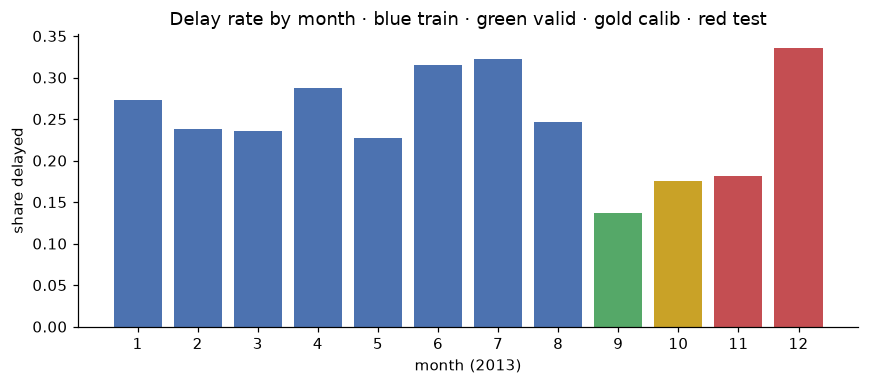

Notice: the delay rate moves a lot between months (September is low, December is high).
This 'base-rate shift' is why we use calibration, lift and rolling folds later.


In [10]:
lab = df[df["delayed"].notna() & (df["date"] > config.WARMUP_END)]
monthly = lab.groupby(lab["date"].dt.month)["delayed"].mean()
colors = ["#4C72B0"] * 8 + ["#55A868", "#C9A227", "#C44E52", "#C44E52"]
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.bar(monthly.index, monthly.values, color=colors[-len(monthly):])
ax.set(xticks=range(1, 13), xlabel="month (2013)", ylabel="share delayed",
       title="Delay rate by month · blue train · green valid · gold calib · red test")
fig.tight_layout(); fig.savefig("reports/figures/01_split_delay_rate.png"); plt.show()
print("Notice: the delay rate moves a lot between months (September is low, December is high).")
print("This 'base-rate shift' is why we use calibration, lift and rolling folds later.")

### Save this notebook's results
Every number used later in the report and slides is saved in `reports/`, so nobody types numbers by hand.

In [11]:
out = {"summary": summary, "split_table": split_table.astype(str).to_dict(orient="records"),
       "monthly_delay_rate": {int(k): round(float(v), 4) for k, v in monthly.items()},
       "valid_always_on_time_accuracy": round(always_on_time_accuracy, 4)}
with open("reports/01_problem_data.json", "w") as f:
    json.dump(out, f, indent=2)
print(json.dumps(out, indent=2)[:900])

{
  "summary": {
    "flights": 336776,
    "cancelled": 8255,
    "diverted": 1175,
    "labelled": 327346,
    "delayed_share_of_labelled": 0.2447
  },
  "split_table": [
    {
      "block": "train",
      "from": "2013-01-15",
      "to": "2013-08-31",
      "flights": "205642",
      "share_%": "65.2",
      "delay_rate": "0.2681"
    },
    {
      "block": "valid",
      "from": "2013-09-01",
      "to": "2013-09-30",
      "flights": "27010",
      "share_%": "8.6",
      "delay_rate": "0.1372"
    },
    {
      "block": "calib",
      "from": "2013-10-01",
      "to": "2013-10-31",
      "flights": "28618",
      "share_%": "9.1",
      "delay_rate": "0.1756"
    },
    {
      "block": "test",
      "from": "2013-11-01",
      "to": "2013-12-31",
      "flights": "53991",
      "share_%": "17.1",
      "delay_rate": "0.2583"
    }
  ],
  "monthly_delay_rate": {
    "1": 0.2727


---
## Summary
* Problem: binary classification, label = arrival delay ≥ 15 min, decided at 05:00 on the day of the flight.
* Data: 336,776 flights (structured, time-indexed), 8,255 cancelled and 1,175 diverted flights without a label.
* Metric: PR AUC first, plus ROC AUC, calibration (Brier/ECE), precision/recall at a threshold, lift and day-block CIs.
* Split: by date. The test months stay locked until notebook 05.

**Next:** notebook 02 explores the training data and builds the preprocessing.

<details><summary><b>Viva questions for this notebook (click)</b></summary>

1. **Why decide at 05:00?** Early enough to act on, and it fixes what is legal: earlier days' outcomes plus the published schedule. We first said "end of the previous day", but about 3% of the previous day's flights land after midnight, so 05:00 is when all history is really known.
2. **Why not accuracy?** "Always on time" scores about 86% accuracy in September and catches no delays.
3. **Why a chronological split?** Same-day flights share weather; a random split leaks that and inflates scores. We always predict future days from past days.
4. **Why are cancelled flights not labelled?** They have no arrival delay, so the label is undefined. Inventing one would add false data.
5. **What is the golden barrier?** Test data stays untouched until the final evaluation; any decision made while looking at it makes the final score biased.
6. **What does PR AUC = 0.258 mean on the test set?** That is what random guessing scores there, because 25.8% of test flights are delayed.
</details>

In [12]:
#@title 📦 Last step · download the files you must commit { display-mode: "form" }
#@markdown Downloads a zip with your module(s) and results. Also do **File → Download → Download .ipynb** (keeps the outputs).
#@markdown Unzip both into your local clone of the repo and commit them.
import glob, zipfile
FILES = [
    'src/fdp/config.py',
    'src/fdp/data.py',
    'src/fdp/metrics.py',
    'reports/01_problem_data.json',
    'reports/figures/01_*.png',
]
paths = sorted({p for pattern in FILES for p in glob.glob(pattern)})
zip_name = "01_outputs.zip"
with zipfile.ZipFile(zip_name, "w") as z:
    for p in paths:
        z.write(p)
print("Packed", len(paths), "files into", zip_name)
for p in paths:
    print("  ", p)
if IN_COLAB:
    from google.colab import files
    files.download(zip_name)

Packed 5 files into 01_outputs.zip
   reports/01_problem_data.json
   reports/figures/01_split_delay_rate.png
   src/fdp/config.py
   src/fdp/data.py
   src/fdp/metrics.py
